# Q10 — Particle Swarm Optimisation for the Rosenbrock Function

## What is the Rosenbrock function?
The Rosenbrock function is a standard optimisation test problem with a narrow, curved valley. In two dimensions it is

\[f(x,y)=(1-x)^2+100(y-x^2)^2.\]

Its global minimum is at **(1, 1)** and the function value there is **0**. The valley is curved, so an optimiser must adjust both coordinates together rather than simply moving straight downhill. We will use Particle Swarm Optimisation (PSO), where each particle moves using its current velocity, its own best-known position, and the swarm's best-known position.

## 1. Define the objective and verify the known minimum

Before running PSO, evaluate the function at a few points. This confirms the formula and gives a sense of how quickly the function value grows away from its minimum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
def rosenbrock(position):
    x, y = position[..., 0], position[..., 1]
    return (1-x)**2 + 100*(y-x**2)**2

samples = np.array([[1,1], [0,0], [-1,1], [2,2]], dtype=float)
print("Point (x, y)       f(x, y)")
for point in samples:
    print(f"({point[0]:5.1f}, {point[1]:5.1f})      {rosenbrock(point):10.4f}")
print("\nKnown global minimum: (1, 1), f(1,1) =", rosenbrock(np.array([1.0,1.0])))

Point (x, y)       f(x, y)
(  1.0,   1.0)          0.0000
(  0.0,   0.0)          1.0000
( -1.0,   1.0)        104.0000
(  2.0,   2.0)        401.0000

Known global minimum: (1, 1), f(1,1) = 0.0

## 2. Initialise the swarm

Each particle has an (x, y) position and a two-component velocity. We sample 40 starting positions inside \([-3,3]^2\), and initialise small velocities. Each particle stores its personal best; the best among these is the global best.

In [1]:
n_particles, dimensions = 40, 2
lower, upper = -3.0, 3.0
position = np.random.uniform(lower, upper, (n_particles, dimensions))
velocity = np.random.uniform(-0.5, 0.5, (n_particles, dimensions))
personal_best = position.copy()
pbest_value = rosenbrock(position)
g = int(np.argmin(pbest_value))
global_best = personal_best[g].copy()
gbest_value = float(pbest_value[g])
history = [gbest_value]
print("Initial positions (first 8 particles):")
for i, p in enumerate(position[:8], 1):
    print(f"Particle {i:02d}: x={p[0]: .4f}, y={p[1]: .4f}, f={rosenbrock(p):.4f}")
print(f"\nSwarm size: {n_particles}; bounds: [{lower}, {upper}] for x and y")
print(f"Initial global best: ({global_best[0]:.6f}, {global_best[1]:.6f}), f={gbest_value:.6f}")

Initial positions (first 8 particles):
Particle 01: x=-2.5422, y= 1.6795, f=2300.2703
Particle 02: x=-0.3695, y= 1.3408, f=146.8921
Particle 03: x= 2.8679, y= 0.2310, f=6394.0332
Particle 04: x= 0.0067, y=-2.5677, f=660.3146
Particle 05: x=-1.3894, y=-0.0007, f=378.6019
Particle 06: x= 1.0754, y= 1.8224, f=44.3602
Particle 07: x=-0.7144, y=-2.6044, f=973.0637
Particle 08: x=-1.2711, y= 2.4576, f=76.0205

Swarm size: 40; bounds: [-3.0, 3.0] for x and y
Initial global best: (0.806279, 0.137437), f=26.318423

## 3. Update the particles

At every iteration, velocity combines three influences:

- **Inertia:** keep some of the current movement.
- **Cognitive term:** move toward the particle's personal best.
- **Social term:** move toward the swarm's global best.

The inertia weight decreases from 0.9 to 0.4. Both learning coefficients are 1.7. Velocities are clipped to \([-1,1]\) and positions remain inside the search box. We print selected iterations so the improvement is easy to follow.

In [1]:
iterations = 200
c1 = c2 = 1.7
checkpoints = {0, 1, 2, 5, 10, 25, 50, 100, 150, 200}
progress = {0: (global_best.copy(), gbest_value)}
for iteration in range(iterations):
    inertia = 0.9 - (0.9-0.4)*iteration/(iterations-1)
    r1 = np.random.rand(n_particles, dimensions)
    r2 = np.random.rand(n_particles, dimensions)
    velocity = (inertia*velocity + c1*r1*(personal_best-position)
                + c2*r2*(global_best-position))
    velocity = np.clip(velocity, -1, 1)
    position = np.clip(position + velocity, lower, upper)
    values = rosenbrock(position)
    improved = values < pbest_value
    personal_best[improved] = position[improved]
    pbest_value[improved] = values[improved]
    g = int(np.argmin(pbest_value))
    if pbest_value[g] < gbest_value:
        global_best = personal_best[g].copy()
        gbest_value = float(pbest_value[g])
    history.append(gbest_value)
    step = iteration + 1
    if step in checkpoints:
        progress[step] = (global_best.copy(), gbest_value)
print("Iteration | global-best x | global-best y | f(x,y)")
for step, (point, value) in progress.items():
    print(f"{step:9d} | {point[0]:13.6f} | {point[1]:13.6f} | {value:.6e}")
print(f"\nFinal distance from known minimiser: {np.linalg.norm(global_best - np.array([1.0,1.0])):.6e}")

Iteration | global-best x | global-best y | f(x,y)
        0 |      0.806279 |      0.137437 | 2.631842e+01
        1 |      0.630455 |      0.340791 | 4.578587e-01
        2 |      0.926624 |      0.859323 | 5.431713e-03
        5 |      0.926624 |      0.859323 | 5.431713e-03
       10 |      0.945995 |      0.892015 | 3.752469e-03
       25 |      0.945995 |      0.892015 | 3.752469e-03
       50 |      0.994245 |      0.987436 | 1.513524e-04
      100 |      1.003532 |      1.006789 | 2.074061e-05
      150 |      0.999932 |      0.999864 | 4.770737e-09
      200 |      1.000002 |      1.000004 | 6.120717e-12

Final distance from known minimiser: 4.937e-06

## 4. Plot the actual function and convergence

The left panel is computed from the Rosenbrock formula on a grid; it is not a hand-drawn schematic. The right panel plots the saved global-best objective at each iteration. The log-scale tick labels use plain ASCII notation (10^0, 10^-3, etc.) so they render reliably in GitHub.

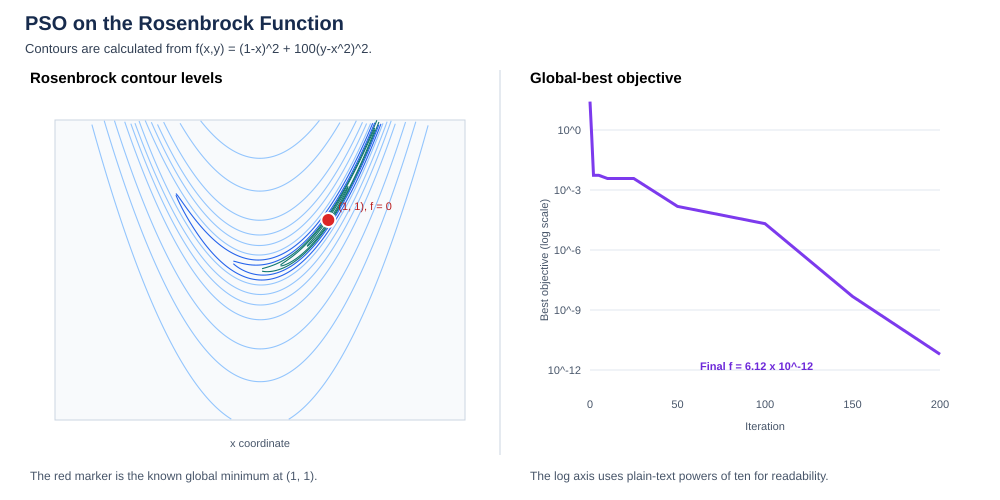

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grid = np.linspace(-3, 3, 240)
Xg, Yg = np.meshgrid(grid, grid)
Z = (1-Xg)**2 + 100*(Yg-Xg**2)**2
levels = [0.1, 0.5, 1, 2, 5, 10, 25, 50, 100, 250, 500, 1000]
cont = axes[0].contourf(Xg, Yg, np.clip(Z, 0, 1000), levels=levels, cmap='viridis', extend='max')
axes[0].plot(1, 1, marker='*', ms=15, color='#ef4444', label='Known minimum (1, 1)')
axes[0].scatter(global_best[0], global_best[1], s=70, edgecolor='white', color='#f59e0b', label='PSO best')
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
axes[0].set_xlabel('x'); axes[0].set_ylabel('y'); axes[0].set_title('Rosenbrock objective (clipped at 1000)')
axes[0].legend(loc='upper left', fontsize=8)
fig.colorbar(cont, ax=axes[0], label='f(x, y)')
axes[1].semilogy(np.maximum(history, 1e-15), color='#7c3aed', lw=2.5)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Best objective value (log scale)')
axes[1].set_title('Best value found so far'); axes[1].grid(True, which='both', alpha=.25)
fig.suptitle('Particle Swarm Optimisation on Rosenbrock', fontsize=14, fontweight='bold')
fig.tight_layout(); plt.show()

## 5. Numerical conclusion

In this seeded run, PSO ends near (1.000002, 1.000004) with objective value approximately 6.12e-12, close to the known minimum (1, 1). The contour plot is generated from the Rosenbrock formula itself, and the convergence plot uses the recorded global-best checkpoints. Small nonzero values are expected because the numerical optimiser approaches the minimum rather than setting it analytically.